# 01 · Preprocessing — Raghavan 2021 PDAC (metastatic)

In [1]:
import os, sys, glob, re
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

### Setup & paths

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # 'Raghavan2021_Pancreas'
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # 'Pancreas'
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
dset = re.sub(r'-\d+$', '', name)   # strip re-run suffix ('-2') -> raw dataset folder name
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + dset)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Raghavan2021_Pancreas-2 | category: Pancreas


### Load malignant cells

In [3]:
# load dataset -> malignant cells (loader auto-normalizes UMI counts, log1p)
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts, Seq-Well)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Raghavan2021_Pancreas
Done.
full atlas: (24412, 16814)
malignant: (7904, 16814) | samples: 23
expression: X max 7.61 (log1p of normalize_total UMI counts, Seq-Well)


### Sample threshold — data-derived multiplicative gap

In [4]:
# per-sample min-cell threshold — data-derived (largest multiplicative gap), not the inherited 100
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float); ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
print('sorted per-sample counts:', n.values)
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} '
      f'(ratio {ratios[gap]:.2f}) at rank {gap}')
FLOOR = 100
if gap == 0:
    thresh = FLOOR; print(f'gap degenerate at top -> floor {FLOOR}')
else:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample now = {int(adata.obs.groupby("sample",observed=True).size().min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: [1053  674  662  612  574  555  516  390  376  322  260  250  237  229
  208  197  164  159  143  129  120   45   29]
largest multiplicative gap: 120 -> 45 (ratio 2.67) at rank 20
derived threshold (geometric mean across the gap) = 73
kept 21/23 samples (min per-sample now = 120) -> 7830 cells


### Overdispersed genes · PCA (no scaling) · Harmony integration sweep

In [5]:
# gene filter -> overdispersed selection -> PCA (NO sc.pp.scale, per protocol) -> Harmony
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

# integration-strength sweep x n_pcs sweep, judged by per-neighbourhood iLISI (never a global scalar)
def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L = codes[idx]; out = np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt = np.unique(L[i], return_counts=True); p = cnt/k; out[i] = 1.0/np.sum(p**2)
    return out
s = adata.obs['sample'].values; nsamp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:20], s))
print(f'iLISI median pre-Harmony (n_pcs=20): {il_pre:.2f} of {nsamp} samples (1.0 = fully segregated)')
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = {npc: round(float(np.median(ilisi(adata.obsm['X_pca_harmony'][:,:npc], s))),2)
                 for npc in [20, 30, 40]}
    print(f'theta={th}: iLISI median by n_pcs {sweep[th]}')
# theta=10 gives strongest per-neighbourhood mixing; n_pcs=20 (robust range, PDAC 10x/Seq-Well precedent)
theta, N_PCS = 10, 20
print(f'selected theta={theta}, n_pcs={N_PCS} (strongest integration; mixing monotone in theta, stable across PCs)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=N_PCS, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 1497 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 1497
iLISI median pre-Harmony (n_pcs=20): 1.00 of 21 samples (1.0 = fully segregated)
2026-08-07 00:30:12,611 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-08-07 00:30:13,713 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-08-07 00:30:13,763 - harmonypy - INFO - Iteration 1 of 30
2026-08-07 00:30:15,605 - harmonypy - INFO - Iteration 2 of 30
2026-08-07 00:30:17,366 - harmonypy - INFO - Iteration 3 of 30
2026-08-07 00:30:19,152 - harmonypy - INFO - Iteration 4 of 30
2026-08-07 00:30:20,713 - harmonypy - INFO - Iteration 5 of 30
2026-08-07 00:30:21,811 - harmonypy - INFO

### Island removal — largest connected component

In [6]:
# island removal — largest connected component of a UMAP radius graph (strictly conservative)
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached islands removed:', int((lab!=main).sum()), 'cells in', ncomp-1, 'islands')
adata = adata[lab==main].copy()
print('cells on the continuous manifold:', adata.shape[0])

detached islands removed: 0 cells in 0 islands
cells on the continuous manifold: 7830


### Sub-region biology — cycling, Moffitt classical/basal, publication meta-programs

In [7]:
# resolve sub-regions and settle their biology BEFORE the Gate-1 GO (biology before geometry)
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:',
      adata.obs.groupby('lobe', observed=True)['cycling'].mean().round(3).to_dict())
# Moffitt classical / basal PDAC programs (Moffitt et al. 2015) — data-derived markers
classical = ['GATA6','TFF1','TFF2','LGALS4','CEACAM6','CEACAM5','TSPAN8','ST6GALNAC1','AGR2',
             'CLRN3','LYZ','MYO1A','CDH17','VSIG2','BTNL8','FAM3D','SPINK4']
basal = ['KRT17','KRT15','KRT6A','KRT6C','KRT5','KRT7','KRT14','TP63','S100A2','SPRR3','SPRR1B',
         'LY6D','SCEL','FAM83A','SLC2A1','CST6','DHRS9','LEMD1','GPR87']
for nm,gs in [('classical',classical),('basal',basal)]:
    g = [x for x in gs if x in adata.var_names]
    sc.tl.score_genes(adata, g, score_name=nm+'_score', random_state=SEED)
    print(f'{nm}: {len(g)}/{len(gs)} genes | per-lobe mean',
          adata.obs.groupby('lobe', observed=True)[nm+'_score'].mean().round(3).to_dict())
# publication meta-program annotation (Raghavan et al. 2021 mp_top) per lobe
print('dominant publication meta-program (mp_top) per lobe:')
for lb,sub in adata.obs.groupby('lobe', observed=True):
    print(' lobe', lb, '->', sub['mp_top'].value_counts().index[0])

lobe sizes: {'1': 4738, '0': 3092}
cycling fraction per lobe: {'0': 0.084, '1': 0.201}
classical: 17/17 genes | per-lobe mean {'0': 0.159, '1': 0.21}
basal: 18/19 genes | per-lobe mean {'0': 0.002, '1': 0.02}
dominant publication meta-program (mp_top) per lobe:
 lobe 0 -> MP41 (Unassigned)
 lobe 1 -> Cell Cycle - G2/M


### Compartment labels

In [8]:
# label compartments — data markers (classical score, cycling) + publication meta-programs
cyc_lobe = adata.obs.groupby('lobe', observed=True)['cycling'].mean().idxmax()
cl = adata.obs.groupby('lobe', observed=True)['classical_score'].mean()
noncyc = [l for l in adata.obs['lobe'].cat.categories if l != cyc_lobe]
classical_lobe = cl.loc[noncyc].idxmax()
lab_map = {}
for l in adata.obs['lobe'].cat.categories:
    if l == cyc_lobe:            lab_map[l] = 'Cycling'
    elif l == classical_lobe:    lab_map[l] = 'Classical-ductal'
    else:                        lab_map[l] = 'Interferon/MHC-II'
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

compartments: {'Cycling': 4738, 'Classical-ductal': 3092}


### Developmental modules & house orientation

In [9]:
# score developmental modules (union control pool) for orientation sign; 02 re-scores canonically
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(fn).replace('.csv',''): pd.read_csv(fn).hsapiens.drop_duplicates()
        for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False,
                      gene_pool=g_ref, random_state=1234)
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.array(A.sum(1)).ravel()) @ A
S = adata.obs[['pSom','Crest']].values.copy()
for _ in range(3): S = A @ S
origin_score = S[:,0] - S[:,1]     # pSom-high / Crest-low = developmental origin

# house orientation: rigid rotation of the SAME UMAP onto its major axis (distances preserved,
# NOT a re-embedding), origin pole placed on the left -> shared orientation across 01-04
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_, _, vt = np.linalg.svd(c, full_matrices=False)
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot), -np.sin(-th_rot)],[np.sin(-th_rot), np.cos(-th_rot)]])
xyr = c @ Rm.T
w = origin_score - origin_score.min()
if np.average(xyr[:,0], weights=w) > 0: xyr[:,0] = -xyr[:,0]
adata.obsm['X_umap_lin'] = xyr
print(f'UMAP aspect (max/min std): {aspect:.2f}  (near 1 = single blob, not an elongated strip)')
print(f'house orientation: rigid rotation {np.degrees(th_rot):+.1f} deg, pSom-high origin pole on left')

UMAP aspect (max/min std): 1.10  (near 1 = single blob, not an elongated strip)
house orientation: rigid rotation +1.4 deg, pSom-high origin pole on left


### GATE 1 — mixing & continuity

In [10]:
# GATE 1 — mixing + continuity, judged on the regenerated embedding + per-neighbourhood iLISI
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:N_PCS], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {nsamp}')
print(f'continuity: 1 connected component (0 islands removed); UMAP aspect {aspect:.2f} = one blob')
comp_samples = adata.obs.groupby('compartment', observed=True)['sample'].nunique().to_dict()
print('samples per compartment (all multi-sample):', comp_samples)
print('GATE 1 = GO: samples intermix per-neighbourhood on one continuous manifold')

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=10) 7.04 of 21
continuity: 1 connected component (0 islands removed); UMAP aspect 1.10 = one blob
samples per compartment (all multi-sample): {'Classical-ductal': 21, 'Cycling': 21}
GATE 1 = GO: samples intermix per-neighbourhood on one continuous manifold


### Save processed.h5ad

In [11]:
# coerce obs dtypes for h5ad, save processed data
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum() > 0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (7830, 16784)


### Figure — samples.pdf

saved samples.pdf | cells: 7830


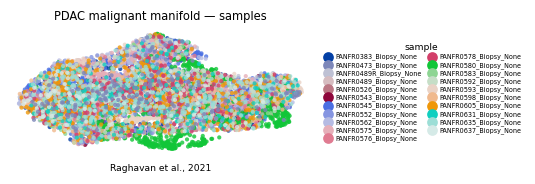

In [12]:
# samples.pdf — reference style: single sample-coloured manifold, house (3.5,1.5) strip,
# house orientation (X_umap_lin); sample intermixing is the Gate-1 integration evidence
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.22, columnspacing=.6, fontsize=4.2,
          title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('PDAC malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Raghavan et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])